In [1]:
import glob
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)

import numpy as np

def calculate_djf_mean(ds):
    ds_seasons = ds.resample(time='QE-FEB').mean()
    ds_djf = ds_seasons.sel(time=(ds_seasons['time.season'] == 'DJF'))
    ds_djf['time'] = pd.date_range(str(ds_djf.time[0].values).split('-')[0], str(int(str(ds_djf.time[-1].values).split('-')[0]) +1), freq='YS-FEB',unit='s')
    return ds_djf


def anomaly_calculation(model, clim):
    ano_list = []
    for i in range(1,13):
        ano_list.append(model.sel(time=model.time[model.time.dt.month.isin(i)]) - clim.sel(month=i))
    return xr.concat(ano_list, dim='time').sortby('time')


def load_climatology(path):
    clim = xr.open_dataset(glob.glob(path)[0])
    clim['time'] = [1,2,3,4,5,6,7,8,9,10,11,12]
    clim = clim.rename({'time': 'month'})
    return clim

def load_data(path):
    ens = []
    ds = []
    for p in glob.glob(path):
        ens.append(p.split('/')[-1].split('_')[4])
        ds.append(xr.open_dataset(p))
    data = xr.concat(ds, dim='ens')
    data['ens'] = ens

    return data

def pressure_weighting(data, plevs=slice(7000,2000)):
    # here I select the pressure level intervall 
    # for which I want to caluculate the layer weights
    # (in this case plevs = 70 - 20 hPa)
    data = data.sel(plev=plevs)
    # Then natural logarithm of this pressure values is caluculated
    log_pressure = np.log(data.plev.values)  
    # the difference between this logaritmic pressure values is made
    log_layer_thickness = np.abs(np.diff(log_pressure))
    # then i devide these differences by the total thickness of the layer
    # = sum of the differences
    log_layer_thickness = log_layer_thickness / sum(log_layer_thickness)

    # this part just creates an array to make it compatible with the data 
    # #(no manipulation of the results done in this step)
    log_layer_thickness = xr.DataArray(
        log_layer_thickness,
        coords={"plev": data.plev.values[:-1]},  # Assign to the lower pressure level of each layer
        dims=["plev"]
    )

    # finally I multiply the data with the "normalized" thickness of the pressure layer
    data = data * log_layer_thickness

    return data.sum(dim='plev')

In [3]:
path = "/sto4/data/Intermediate/VolMIP/pinatubo-full/"
path_piControl = "/sto4/data/Intermediate/VolMIP/piControl/"
models = ['CanESM5', 'GISS-E2-1-G', 'IPSL-CM6A-LR', 'MIROC-ES2L', 'MPI-ESM1-2-LR', 'UKESM1-0-LL']
plotdir = '/home/kperny/VolMIP_stratosphere/plots/NAM/'

nam_flags = pd.read_csv('/home/kperny/VolMIP_stratosphere/tab/nam_flags.csv')
nam_flags = nam_flags.set_index(['model', 'realization'])

# read pre-calculated table for piControl
df_pi_control = pd.read_csv('/home/kperny/VolMIP_stratosphere/tab/diagnostics_piControl.csv')
df_pi_control = df_pi_control.set_index(['model', 'realization'])
df_pi_control[nam_flags.columns[1:]] = nam_flags[nam_flags.columns[1:]]

In [4]:
nam_flags

year  nam_1000_pi  nam_10_pi  nam_1000_volc  \
model       realization                                                      
CanESM5     r1i1p2f1     5552-02-01     0.626101   0.554383       1.589151   
            r2i1p2f1     5557-02-01     0.305675   1.020835      -1.331237   
            r3i1p2f1     5575-02-01     1.150041   0.151298       0.225156   
            r4i1p2f1     5622-02-01     0.550139   0.991791       0.607549   
            r5i1p2f1     5643-02-01     1.007378  -0.248205      -0.585623   
...                             ...          ...        ...            ...   
UKESM1-0-LL r21i1p1f2    3123-02-01     1.604986   0.324822       1.159537   
            r22i1p1f2    3074-02-01     0.957727   0.521336      -0.904977   
            r23i1p1f2    3104-02-01     1.522743  -0.845900       0.511008   
            r24i1p1f2    3077-02-01     0.655677  -0.903783      -1.506172   
            r25i1p1f2    3181-02-01     1.000508  -0.155986      -0.001972   

                         nam_10_volc  flag_1000_pi  flag_10_pi  \
model       realization                                          
CanESM5     r1i1p2f1        0.002030           1.0         0.0   
            r2i1p2f1       -2.436064           0.0         1.0   
            r3i1p2f1        0.971776           1.0         0.0   
            r4i1p2f1        0.033153           1.0         1.0   
            r5i1p2f1        0.327150           1.0         0.0   
...                              ...           ...         ...   
UKESM1-0-LL r21i1p1f2      -0.554986           1.0         0.0   
            r22i1p1f2      -1.151654           1.0         0.0   
            r23i1p1f2      -0.484642           1.0        -1.0   
            r24i1p1f2      -1.233645           1.0        -1.0   
            r25i1p1f2      -0.757300           1.0         0.0   

                         flag_1000_volc  flag_10_volc  
model       realization                                
CanESM5     r1i1p2f1                1.0           0.0  
            r2i1p2f1               -1.0          -1.0  
            r3i1p2f1                0.0           1.0  
            r4i1p2f1                1.0           0.0  
            r5i1p2f1               -1.0           0.0  
...                                 ...           ...  
UKESM1-0-LL r21i1p1f2               1.0          -1.0  
            r22i1p1f2              -1.0          -1.0  
            r23i1p1f2               0.0          -1.0  
            r24i1p1f2              -1.0          -1.0  
            r25i1p1f2               0.0          -1.0  

[261 rows x 9 columns]

In [5]:
# volc_nao_flags = pd.read_csv('/home/kperny/VolMIP_stratosphere/tab/nao_change.csv')
# # volc_nao_flags = volc_nao_flags.set_index(['model', 'realization'])
# df_volc = nao_flags.where(volc_nao_flags.experiment=='volc').dropna().drop('experiment', axis=1)
df_volc = nam_flags.drop(['year', 'nam_1000_pi', 'nam_10_pi', 'nam_1000_volc', 'nam_10_volc', 'flag_1000_pi', 'flag_10_pi'], axis=1)

# model = models[0]
for model in models:
    ta_volc = load_data(path + model + '/ta_AmonZ_*.nc')
    ua_volc = load_data(path + model + '/ua_AmonZ_*.nc')
    ua_clim_pi = load_climatology(path_piControl + model + '/ua_clim_AmonZ*')
    ta_clim_pi = load_climatology(path_piControl + model + '/ta_clim_AmonZ*')

    ta_ano = anomaly_calculation(ta_volc['ta'], ta_clim_pi['ta'])
    ta_volc = calculate_djf_mean(ta_ano)

    ua_ano = anomaly_calculation(ua_volc['ua'], ua_clim_pi['ua'])
    ua_volc = calculate_djf_mean(ua_ano)

    df_volc.loc[model,'deltaT_tropics'] = pressure_weighting(ta_volc.sel(time='1992-02')).sel(lat=slice(-20,20)).mean('lat').squeeze().sel(ens=df_volc.loc[model].index).values
    df_volc.loc[model,'deltaT_polar'] = pressure_weighting(ta_volc.sel(time='1992-02')).sel(lat=slice(70,90)).mean('lat').squeeze().sel(ens=df_volc.loc[model].index).values
    df_volc.loc[model,'deltaU'] = ua_volc.sel(time='1992-02').sel(lat=slice(60,70), plev=1000).mean('lat').squeeze().sel(ens=df_volc.loc[model].index).values


/tmp/ipykernel_3228859/1070168184.py:27: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  clim = xr.open_dataset(glob.glob(path)[0])
/tmp/ipykernel_3228859/1070168184.py:27: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  clim = xr.open_dataset(glob.glob(path)[0])
/tmp/ipykernel_3228859/1070168184.py:37: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds.append(x

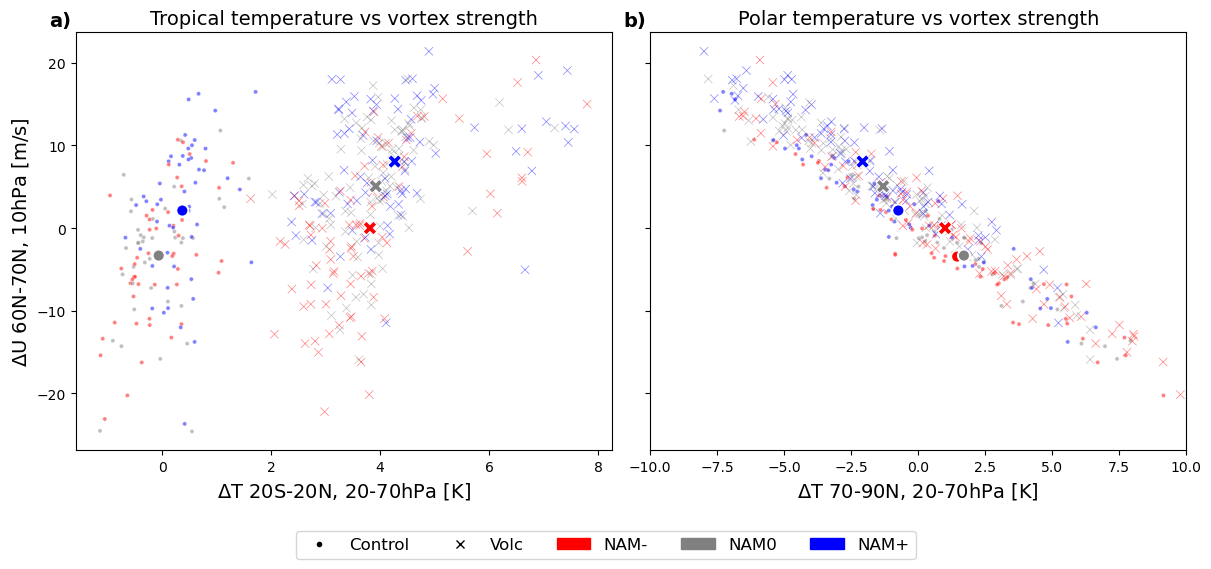

In [6]:
fig, axs = plt.subplots(1,2, figsize=(12,5), sharey=True, layout='constrained')
colors = ['red', 'grey', 'blue']

# for i, model in enumerate(models):
c = sns.scatterplot(df_pi_control.reset_index(), x='deltaT_tropics', y='deltaU', hue='flag_1000_pi', palette=colors, marker='.', alpha=0.5, ax=axs[0], legend=False)
c = sns.scatterplot(df_pi_control.drop('year', axis=1).groupby('flag_1000_pi').mean(), x='deltaT_tropics', y='deltaU', hue='flag_1000_pi', palette=colors, marker='.', s=300, ax=axs[0], legend=False)
e = sns.scatterplot(df_volc.reset_index(), x='deltaT_tropics', y='deltaU', hue='flag_1000_volc', palette=colors, marker='x', alpha=0.5, ax=axs[0], legend=False)
e = sns.scatterplot(df_volc.groupby('flag_1000_volc').mean(), x='deltaT_tropics', y='deltaU', hue='flag_1000_volc', palette=colors, marker='X', s=100, ax=axs[0], legend=False)

sns.scatterplot(df_pi_control.reset_index(), x='deltaT_polar', y='deltaU', hue='flag_1000_pi', palette=colors, marker='.', alpha=0.5, ax=axs[1], legend=False)
sns.scatterplot(df_volc.reset_index(), x='deltaT_polar', y='deltaU', hue='flag_1000_volc', palette=colors, marker='x', alpha=0.5, ax=axs[1], legend=False)
sns.scatterplot(df_pi_control.drop('year', axis=1).groupby('flag_1000_pi').mean(), x='deltaT_polar', y='deltaU', hue='flag_1000_pi', palette=colors, marker='.', s=300, ax=axs[1], legend=False)
sns.scatterplot(df_volc.groupby('flag_1000_volc').mean(), x='deltaT_polar', y='deltaU', hue='flag_1000_volc', palette=colors, marker='X', s=100, ax=axs[1], legend=False)

axs[1].set_xlim(-10,10)

axs[0].set_xlabel('$\Delta$T 20S-20N, 20-70hPa [K]', fontsize=14)
axs[1].set_xlabel('$\Delta$T 70-90N, 20-70hPa [K]', fontsize=14)
axs[0].set_ylabel('$\Delta$U 60N-70N, 10hPa [m/s]', fontsize=14)

axs[0].set_title('Tropical temperature vs vortex strength', fontsize=14)
axs[1].set_title('Polar temperature vs vortex strength', fontsize=14)

axs[0].annotate('a)', xy=(-0.05, 1.05), weight='bold', color='k', xycoords='axes fraction', fontsize=14, ha='left', va='top')
axs[1].annotate('b)', fontsize=14, weight='bold', color='k', xy=(-0.05, 1.05), xycoords='axes fraction', ha='left', va='top')
# legend
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches

piControl = Line2D([0], [0], label='Control', color='black', marker='.', linestyle='None')
volc = Line2D([0], [0], label='Volc', color='black', linestyle='None', marker='x')
all = mpatches.Patch(color='k', alpha=0.8, label='All')
blue_patch = mpatches.Patch(color='blue', label='NAM+')
grey_patch = mpatches.Patch(color='grey', label='NAM0')
red_patch = mpatches.Patch(color='red', label='NAM-')
fig.legend(handles=[piControl, volc, red_patch, grey_patch, blue_patch], loc='center', ncol=5, fontsize=12, bbox_to_anchor=(0.5,-0.08))

plt.savefig(plotdir + 'figure2_1000.png', dpi=200, bbox_inches='tight')

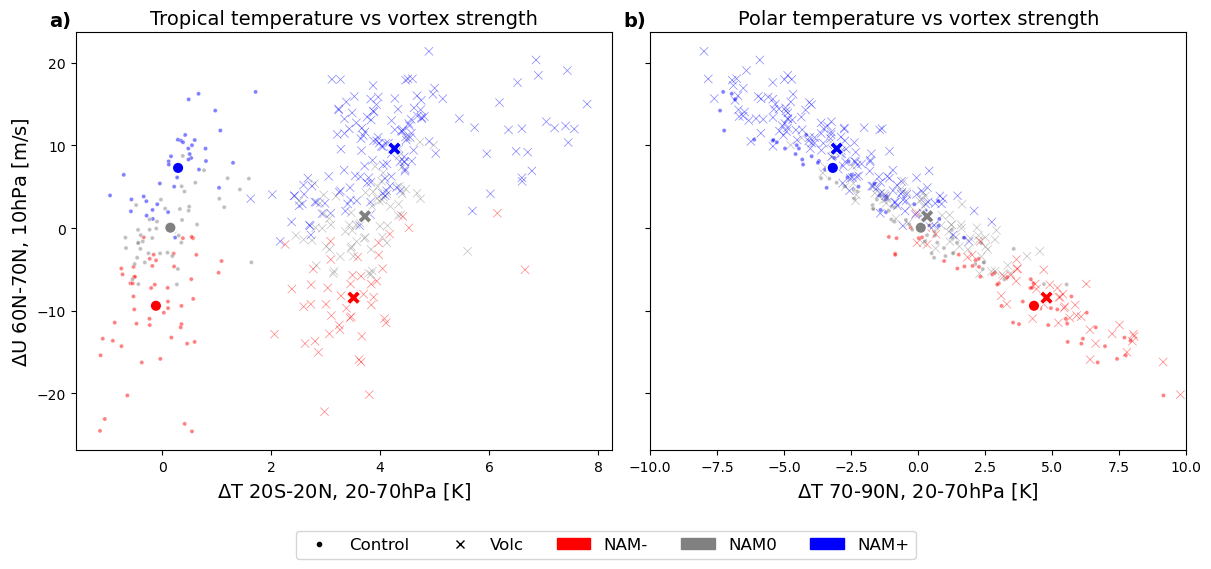

In [7]:
fig, axs = plt.subplots(1,2, figsize=(12,5), sharey=True, layout='constrained')
colors = ['red', 'grey', 'blue']

# for i, model in enumerate(models):
c = sns.scatterplot(df_pi_control.reset_index(), x='deltaT_tropics', y='deltaU', hue='flag_10_pi', palette=colors, marker='.', alpha=0.5, ax=axs[0], legend=False)
c = sns.scatterplot(df_pi_control.drop('year', axis=1).groupby('flag_10_pi').mean(), x='deltaT_tropics', y='deltaU', hue='flag_10_pi', palette=colors, marker='.', s=300, ax=axs[0], legend=False)
e = sns.scatterplot(df_volc.reset_index(), x='deltaT_tropics', y='deltaU', hue='flag_10_volc', palette=colors, marker='x', alpha=0.5, ax=axs[0], legend=False)
e = sns.scatterplot(df_volc.groupby('flag_10_volc').mean(), x='deltaT_tropics', y='deltaU', hue='flag_10_volc', palette=colors, marker='X', s=100, ax=axs[0], legend=False)

sns.scatterplot(df_pi_control.reset_index(), x='deltaT_polar', y='deltaU', hue='flag_10_pi', palette=colors, marker='.', alpha=0.5, ax=axs[1], legend=False)
sns.scatterplot(df_volc.reset_index(), x='deltaT_polar', y='deltaU', hue='flag_10_volc', palette=colors, marker='x', alpha=0.5, ax=axs[1], legend=False)
sns.scatterplot(df_pi_control.drop('year', axis=1).groupby('flag_10_pi').mean(), x='deltaT_polar', y='deltaU', hue='flag_10_pi', palette=colors, marker='.', s=300, ax=axs[1], legend=False)
sns.scatterplot(df_volc.groupby('flag_10_volc').mean(), x='deltaT_polar', y='deltaU', hue='flag_10_volc', palette=colors, marker='X', s=100, ax=axs[1], legend=False)

axs[1].set_xlim(-10,10)

axs[0].set_xlabel('$\Delta$T 20S-20N, 20-70hPa [K]', fontsize=14)
axs[1].set_xlabel('$\Delta$T 70-90N, 20-70hPa [K]', fontsize=14)
axs[0].set_ylabel('$\Delta$U 60N-70N, 10hPa [m/s]', fontsize=14)

axs[0].set_title('Tropical temperature vs vortex strength', fontsize=14)
axs[1].set_title('Polar temperature vs vortex strength', fontsize=14)

axs[0].annotate('a)', xy=(-0.05, 1.05), weight='bold', color='k', xycoords='axes fraction', fontsize=14, ha='left', va='top')
axs[1].annotate('b)', fontsize=14, weight='bold', color='k', xy=(-0.05, 1.05), xycoords='axes fraction', ha='left', va='top')
# legend
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches

piControl = Line2D([0], [0], label='Control', color='black', marker='.', linestyle='None')
volc = Line2D([0], [0], label='Volc', color='black', linestyle='None', marker='x')
all = mpatches.Patch(color='k', alpha=0.8, label='All')
blue_patch = mpatches.Patch(color='blue', label='NAM+')
grey_patch = mpatches.Patch(color='grey', label='NAM0')
red_patch = mpatches.Patch(color='red', label='NAM-')
fig.legend(handles=[piControl, volc, red_patch, grey_patch, blue_patch], loc='center', ncol=5, fontsize=12, bbox_to_anchor=(0.5,-0.08))

plt.savefig(plotdir + 'figure2_10.png', dpi=200, bbox_inches='tight')

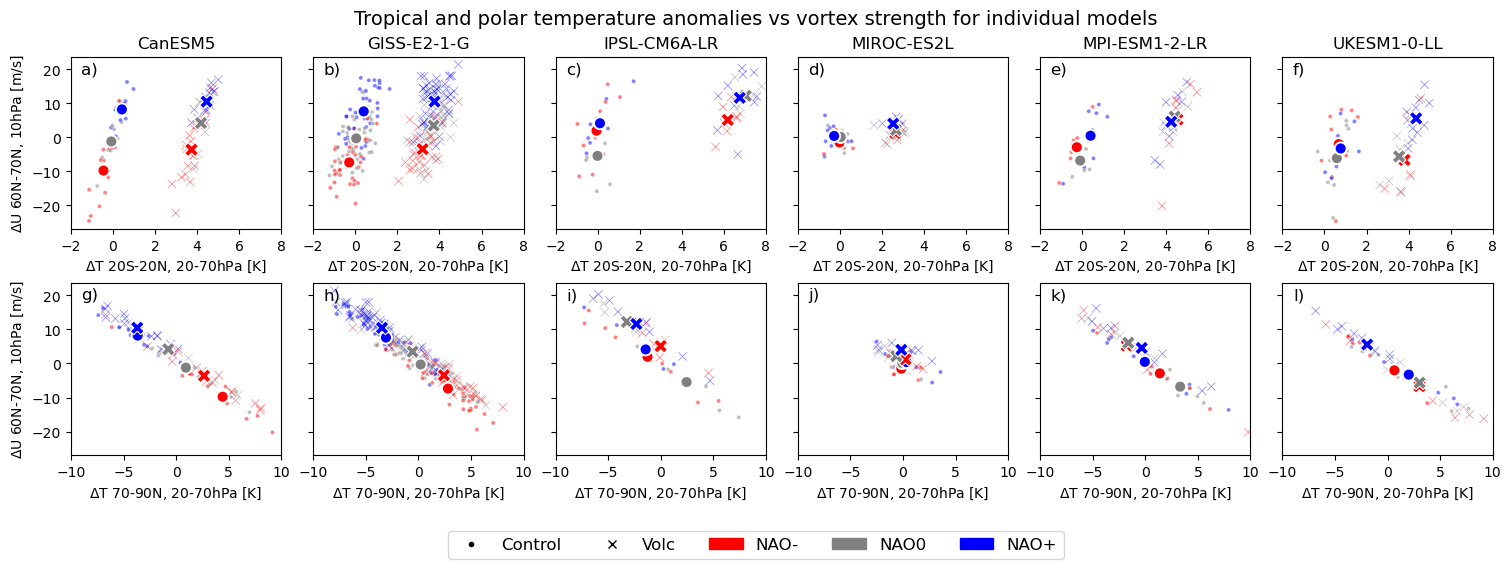

In [13]:
fig, axs = plt.subplots(2,6, figsize=(15,5), sharey=True, layout='constrained')
colors = ['red', 'grey', 'blue']

alist = ['a)', 'b)', 'c)', 'd)', 'e)', 'f)']
blist = ['g)', 'h)', 'i)', 'j)', 'k)', 'l)']
for i, model in enumerate(models):
    c = sns.scatterplot(df_pi_control.loc[model].reset_index(), x='deltaT_tropics', y='deltaU', hue='flag_pi', palette=colors, marker='.', alpha=0.5, ax=axs[0, i], legend=False)
    c = sns.scatterplot(df_pi_control.loc[model].drop('year', axis=1).groupby('flag_pi').mean(), x='deltaT_tropics', y='deltaU', hue='flag_pi', palette=colors, marker='.', s=300, ax=axs[0, i], legend=False)
    e = sns.scatterplot(df_volc.loc[model].reset_index(), x='deltaT_tropics', y='deltaU', hue='flag_volc', palette=colors, marker='x', alpha=0.5, ax=axs[0, i], legend=False)
    e = sns.scatterplot(df_volc.loc[model].groupby('flag_volc').mean(), x='deltaT_tropics', y='deltaU', hue='flag_volc', palette=colors, marker='X', s=100, ax=axs[0, i], legend=False)
    # d = sns.scatterplot(df_volc_clim.loc[model].reset_index(), x='deltaT_tropics', y='deltaU', hue='flag_volc', palette=colors, marker='+', ax=axs[0, i], legend=False)

    axs[0,i].set_xlabel('$\Delta$T 20S-20N, 20-70hPa [K]')
    axs[0,i].set_xlim(-2,8)

    sns.scatterplot(df_pi_control.loc[model].reset_index(), x='deltaT_polar', y='deltaU', hue='flag_pi', palette=colors, marker='.', alpha=0.5, ax=axs[1, i], legend=False)
    sns.scatterplot(df_volc.loc[model].reset_index(), x='deltaT_polar', y='deltaU', hue='flag_volc', palette=colors, marker='x', alpha=0.5, ax=axs[1, i], legend=False)
    sns.scatterplot(df_pi_control.loc[model].drop('year', axis=1).groupby('flag_pi').mean(), x='deltaT_polar', y='deltaU', hue='flag_pi', palette=colors, marker='.', s=300, ax=axs[1, i], legend=False)
    sns.scatterplot(df_volc.loc[model].groupby('flag_volc').mean(), x='deltaT_polar', y='deltaU', hue='flag_volc', palette=colors, marker='X', s=100, ax=axs[1, i], legend=False)

    axs[1,i].set_xlim(-10,10)
    axs[1,i].set_xlabel('$\Delta$T 70-90N, 20-70hPa [K]')

    axs[0,i].set_title(model)

    axs[0,i].annotate(alist[i], (0.05,0.93), xycoords='axes fraction', va='center', fontsize=12)
    axs[1,i].annotate(blist[i], (0.05,0.93), xycoords='axes fraction', va='center', fontsize=12)
axs[0,0].set_ylabel('$\Delta$U 60N-70N, 10hPa [m/s]')
axs[1,0].set_ylabel('$\Delta$U 60N-70N, 10hPa [m/s]')


# legend
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches

piControl = Line2D([0], [0], label='Control', color='black', marker='.', linestyle='None')
volc = Line2D([0], [0], label='Volc', color='black', linestyle='None', marker='x')
all = mpatches.Patch(color='k', alpha=0.8, label='All')
blue_patch = mpatches.Patch(color='blue', label='NAO+')
grey_patch = mpatches.Patch(color='grey', label='NAO0')
red_patch = mpatches.Patch(color='red', label='NAO-')
fig.legend(handles=[piControl, volc, red_patch, grey_patch, blue_patch], loc='center', ncol=5, fontsize=12, bbox_to_anchor=(0.5,-0.08))

plt.suptitle('Tropical and polar temperature anomalies vs vortex strength for individual models', fontsize=14)
plt.savefig(plotdir + 'supp4.png', dpi=200, bbox_inches='tight')

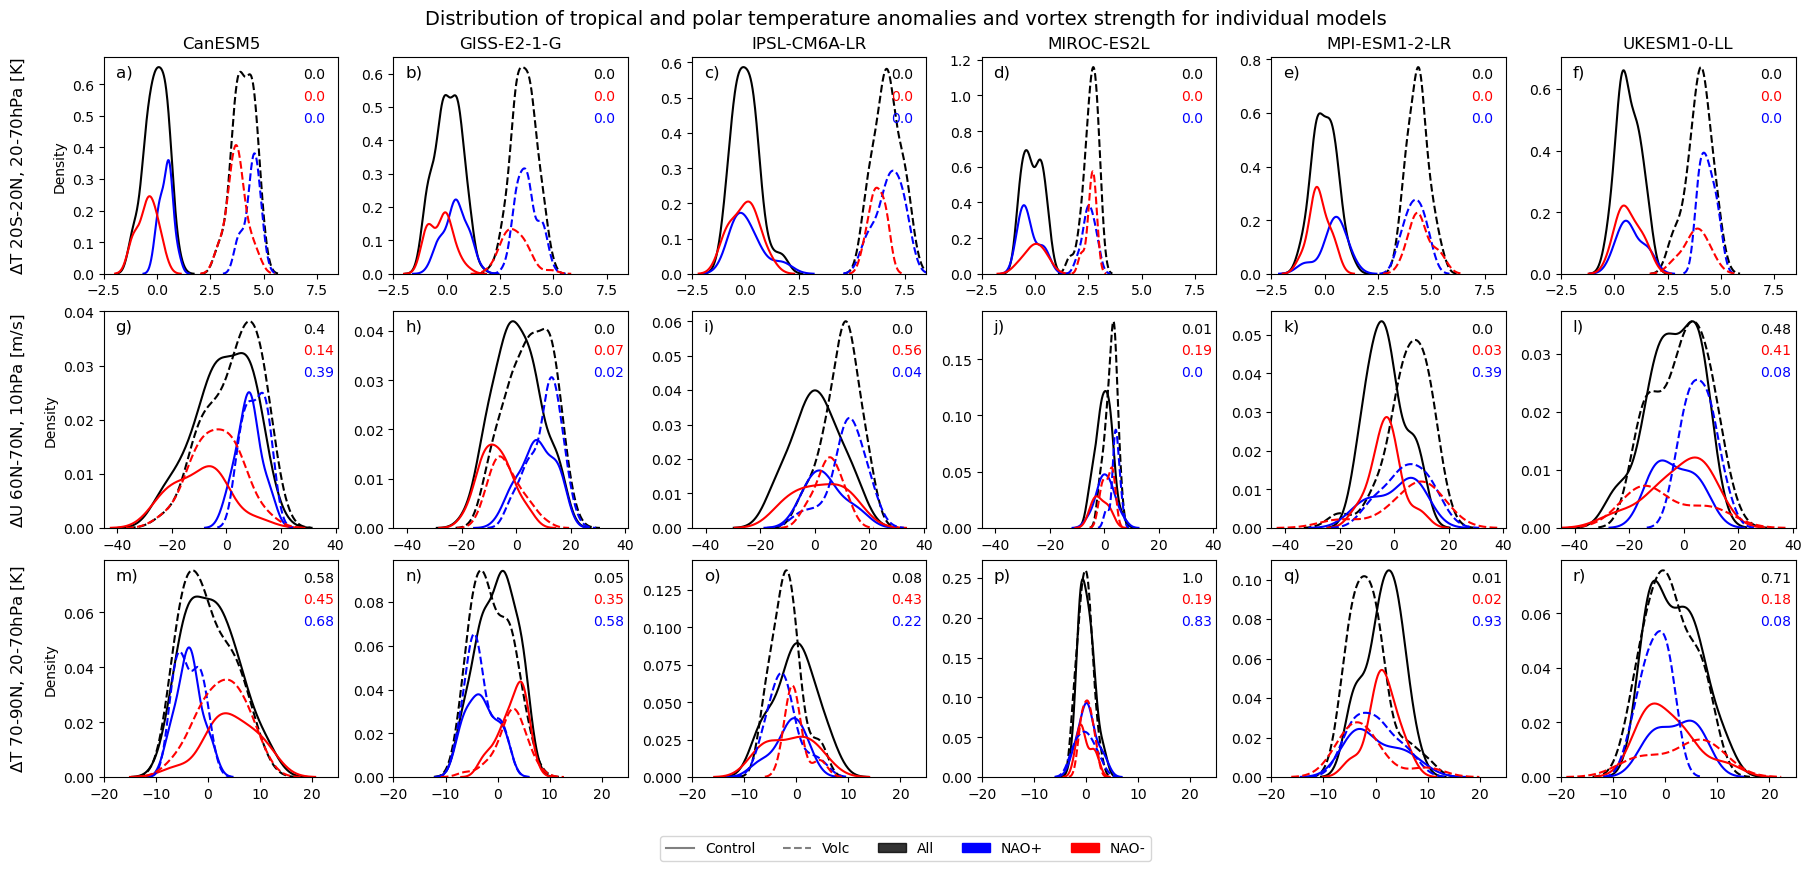

In [11]:
fig, axs = plt.subplots(3,6, figsize=(18,8), layout='constrained')

alist = ['a)', 'b)', 'c)', 'd)', 'e)','f)']
blist = [ 'g)', 'h)', 'i)', 'j)','k)', 'l)']
clist = [ 'm)', 'n)', 'o)', 'p)','q)', 'r)']

for i, model in enumerate(models):
    all_pi = df_pi_control.loc[model]
    all_volc = df_volc.loc[model]

    sns.kdeplot(all_pi, x='deltaT_tropics', color='k', ax=axs[0, i])
    sns.kdeplot(all_volc, x='deltaT_tropics', c='k', linestyle='--', ax=axs[0, i], legend=False)
    sns.kdeplot(all_pi, x='deltaT_tropics', ax=axs[0, i], hue='flag_pi', palette=['red', 'grey', 'blue'], legend=False)
    lines = sns.kdeplot(all_volc, x='deltaT_tropics', linestyle='--', ax=axs[0, i], hue='flag_volc', palette=['red', 'grey', 'blue'], legend=False)

    lines.lines[3].remove()
    lines.lines[5].remove()

    sns.kdeplot(all_pi, x='deltaU', color='k', ax=axs[1, i])
    sns.kdeplot(all_volc, x='deltaU', c='k', linestyle='--', ax=axs[1, i], legend=False)
    sns.kdeplot(all_pi, x='deltaU', ax=axs[1, i], hue='flag_pi', palette=['red', 'grey', 'blue'], legend=False)
    lines = sns.kdeplot(all_volc, x='deltaU', linestyle='--', ax=axs[1, i], hue='flag_volc', palette=['red', 'grey', 'blue'], legend=False)

    lines.lines[3].remove()
    lines.lines[5].remove()

    sns.kdeplot(all_pi, x='deltaT_polar', color='k', ax=axs[2, i])
    sns.kdeplot(all_volc, x='deltaT_polar', c='k', linestyle='--', ax=axs[2, i], legend=False)
    sns.kdeplot(all_pi, x='deltaT_polar', ax=axs[2, i], hue='flag_pi', palette=['red', 'grey', 'blue'], legend=False)
    lines = sns.kdeplot(all_volc, x='deltaT_polar', linestyle='--', ax=axs[2, i], hue='flag_volc', palette=['red', 'grey', 'blue'], legend=False)

    lines.lines[3].remove()
    lines.lines[5].remove()

    axs[0,i].annotate(alist[i], (0.05,0.93), xycoords='axes fraction', va='center', fontsize=12)
    axs[1,i].annotate(blist[i], (0.05,0.93), xycoords='axes fraction', va='center', fontsize=12)
    axs[2,i].annotate(clist[i], (0.05,0.93), xycoords='axes fraction', va='center', fontsize=12)

    props = None #dict(facecolor='white', alpha=0.7, edgecolor='none')
    posnao_pi = df_pi_control.where(df_pi_control.flag_pi == 1).dropna().loc[model]
    negnao_pi = df_pi_control.where(df_pi_control.flag_pi == -1).dropna().loc[model]
    posnao_volc = df_volc.where(df_volc.flag_volc == 1).dropna().loc[model]
    negnao_volc = df_volc.where(df_volc.flag_volc == -1).dropna().loc[model]

    axs[0,i].text(0.85, 0.9, str(stats.kstest(all_pi.deltaT_tropics.values , all_volc.deltaT_tropics.values)[1].round(2)), transform=axs[0,i].transAxes, bbox=props, c='k')
    axs[0,i].text(0.85, 0.8, str(stats.kstest(negnao_pi.deltaT_tropics.values , negnao_volc.deltaT_tropics.values)[1].round(2)), transform=axs[0,i].transAxes, bbox=props, c='r')
    axs[0,i].text(0.85, 0.7, str(stats.kstest(posnao_pi.deltaT_tropics.values , posnao_volc.deltaT_tropics.values)[1].round(2)), transform=axs[0,i].transAxes, bbox=props, c='b')
    axs[2,i].text(0.85, 0.9, str(stats.kstest(all_pi.deltaT_polar.values , all_volc.deltaT_polar.values)[1].round(2)), transform=axs[2,i].transAxes, bbox=props, c='k')
    axs[2,i].text(0.85, 0.8, str(stats.kstest(negnao_pi.deltaT_polar.values , negnao_volc.deltaT_polar.values)[1].round(2)), transform=axs[2,i].transAxes, bbox=props, c='r')
    axs[2,i].text(0.85, 0.7, str(stats.kstest(posnao_pi.deltaT_polar.values , posnao_volc.deltaT_polar.values)[1].round(2)), transform=axs[2,i].transAxes, bbox=props, c='b')
    axs[1,i].text(0.85, 0.9, str(stats.kstest(all_pi.deltaU.values , all_volc.deltaU.values)[1].round(2)), transform=axs[1,i].transAxes, bbox=props, c='k')
    axs[1,i].text(0.85, 0.8, str(stats.kstest(negnao_pi.deltaU.values , negnao_volc.deltaU.values)[1].round(2)), transform=axs[1,i].transAxes, bbox=props, c='r')
    axs[1,i].text(0.85, 0.7, str(stats.kstest(posnao_pi.deltaU.values , posnao_volc.deltaU.values)[1].round(2)), transform=axs[1,i].transAxes, bbox=props, c='b')

    axs[0,i].set_title(model)
    axs[0,i].set_xlim(-2.5,8.5)
    axs[1,i].set_xlim(-45,41)
    axs[2,i].set_xlim(-20,25)
    axs[0,i].set_ylabel('')
    axs[1,i].set_ylabel('')
    axs[2,i].set_ylabel('')
    axs[0,i].set_xlabel('')
    axs[1,i].set_xlabel('')
    axs[2,i].set_xlabel('')

axs[0,0].set_ylabel('Density')   
axs[1,0].set_ylabel('Density')   
axs[2,0].set_ylabel('Density')   

axs[0,0].annotate('$\Delta$T 20S-20N, 20-70hPa [K]', (-0.4,0.5), xycoords='axes fraction', va='center', rotation=90, fontsize=12)
axs[1,0].annotate('$\Delta$U 60N-70N, 10hPa [m/s]', (-0.4,0.5), xycoords='axes fraction', va='center', rotation=90, fontsize=12)
axs[2,0].annotate('$\Delta$T 70-90N, 20-70hPa [K]', (-0.4,0.5), xycoords='axes fraction', va='center', rotation=90, fontsize=12)

plt.suptitle('Distribution of tropical and polar temperature anomalies and vortex strength for individual models', fontsize=14)

from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
piControl = Line2D([0], [0], label='Control', color='grey')
volc = Line2D([0], [0], label='Volc', color='grey', linestyle='--')
all = mpatches.Patch(color='k', alpha=0.8, label='All')
ponao = mpatches.Patch(color='blue', label='NAO+')
negnao = mpatches.Patch(color='red', label='NAO-')

fig.legend(handles= [piControl, volc, all, ponao, negnao], loc='upper center', bbox_to_anchor=(0.5, -0.03), ncol=5)

plt.savefig(plotdir + 'supp5.png', dpi=200, bbox_inches='tight')

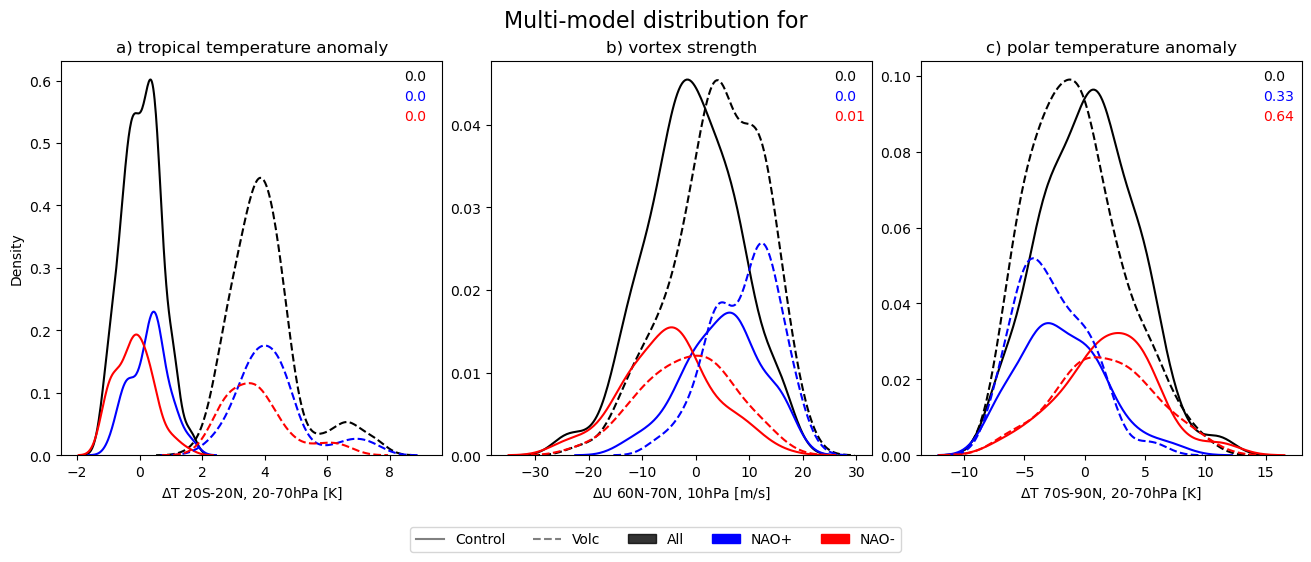

In [10]:
fig, axs = plt.subplots(1,3, figsize=(13,5), layout='constrained')

posnao_pi = df_pi_control.where(df_pi_control.flag_pi == 1).dropna()
negnao_pi = df_pi_control.where(df_pi_control.flag_pi == -1).dropna()

posnao_volc = df_volc.where(df_volc.flag_volc == 1).dropna()
negnao_volc = df_volc.where(df_volc.flag_volc == -1).dropna()

sns.kdeplot(df_pi_control, x='deltaT_tropics', color='black', ax=axs[0])
sns.kdeplot(df_volc, x='deltaT_tropics', color='black', ax=axs[0], linestyle='--')
sns.kdeplot(df_pi_control, x='deltaT_tropics', ax=axs[0], hue='flag_pi', palette=['red', 'grey', 'blue'], legend=False)
lines = sns.kdeplot(df_volc, x='deltaT_tropics', ax=axs[0], linestyle='--', hue='flag_volc', palette=['red', 'grey', 'blue'], legend=False)

lines.lines[3].remove()
lines.lines[5].remove()

sns.kdeplot(df_pi_control, x='deltaU', color='black', ax=axs[1])
sns.kdeplot(df_volc, x='deltaU', color='black', ax=axs[1], linestyle='--')
sns.kdeplot(df_pi_control, x='deltaU', ax=axs[1], hue='flag_pi', palette=['red', 'grey', 'blue'], legend=False)
lines = sns.kdeplot(df_volc, x='deltaU', ax=axs[1], linestyle='--', hue='flag_volc', palette=['red', 'grey', 'blue'], legend=False)

lines.lines[3].remove()
lines.lines[5].remove()

sns.kdeplot(df_pi_control, x='deltaT_polar', color='black', ax=axs[2])
sns.kdeplot(df_volc, x='deltaT_polar', color='black', ax=axs[2], linestyle='--')
sns.kdeplot(df_pi_control, x='deltaT_polar', ax=axs[2], hue='flag_pi', palette=['red', 'grey', 'blue'], legend=False)
lines = sns.kdeplot(df_volc, x='deltaT_polar', ax=axs[2], linestyle='--', hue='flag_volc', palette=['red', 'grey', 'blue'], legend=False)

lines.lines[3].remove()
lines.lines[5].remove()

props = None #dict(facecolor='white', alpha=0.7, edgecolor='none')

axs[0].text(0.90, 0.95, str(stats.kstest(df_pi_control.deltaT_tropics.values , df_volc.deltaT_tropics.values)[1].round(3)), c='k', transform=axs[0].transAxes, bbox=props)
axs[0].text(0.90, 0.9,  str(stats.kstest(posnao_pi.deltaT_tropics.values , posnao_volc.deltaT_tropics.values)[1].round(3)), c='b', transform=axs[0].transAxes, bbox=props)
axs[0].text(0.90, 0.85, str(stats.kstest(negnao_pi.deltaT_tropics.values , negnao_volc.deltaT_tropics.values)[1].round(3)), c='r',transform=axs[0].transAxes, bbox=props)
axs[1].text(0.90, 0.95, str(stats.kstest(df_pi_control.deltaU.values , df_volc.deltaU.values)[1].round(2)), c='k', transform=axs[1].transAxes, bbox=props)
axs[1].text(0.90, 0.9,  str(stats.kstest(posnao_pi.deltaU.values , posnao_volc.deltaU.values)[1].round(2)), c='b', transform=axs[1].transAxes, bbox=props)
axs[1].text(0.90, 0.85, str(stats.kstest(negnao_pi.deltaU.values , negnao_volc.deltaU.values)[1].round(2)), c='r',transform=axs[1].transAxes, bbox=props)
axs[2].text(0.90, 0.95, str(stats.kstest(df_pi_control.deltaT_polar.values , df_volc.deltaT_polar.values)[1].round(2)), c='k', transform=axs[2].transAxes, bbox=props)
axs[2].text(0.90, 0.9,  str(stats.kstest(posnao_pi.deltaT_polar.values , posnao_volc.deltaT_polar.values,)[1].round(2)), c='b', transform=axs[2].transAxes, bbox=props)
axs[2].text(0.90, 0.85, str(stats.kstest(negnao_pi.deltaT_polar.values , negnao_volc.deltaT_polar.values)[1].round(2)), c='r',transform=axs[2].transAxes, bbox=props)

axs[0].set_xlabel('$\Delta$T 20S-20N, 20-70hPa [K]')
axs[1].set_xlabel('$\Delta$U 60N-70N, 10hPa [m/s]')
axs[2].set_xlabel('$\Delta$T 70S-90N, 20-70hPa [K]')
axs[1].set_ylabel('')
axs[2].set_ylabel('')

# axs[0].annotate('a)', xy=(-0.05, 1.05), weight='bold', color='k', xycoords='axes fraction', fontsize=14, ha='left', va='top')
# axs[1].annotate('b)', fontsize=14, weight='bold', color='k', xy=(-0.05, 1.05), xycoords='axes fraction', ha='left', va='top')
# axs[2].annotate('c)', fontsize=14, weight='bold', color='k', xy=(-0.05, 1.05), xycoords='axes fraction', ha='left', va='top')

from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
piControl = Line2D([0], [0], label='Control', color='grey')
volc = Line2D([0], [0], label='Volc', color='grey', linestyle='--')
all = mpatches.Patch(color='k', alpha=0.8, label='All')
ponao = mpatches.Patch(color='blue', label='NAO+')
negnao = mpatches.Patch(color='red', label='NAO-')

fig.legend(handles= [piControl, volc, all, ponao, negnao], loc='upper center', bbox_to_anchor=(0.5, -0.03), ncol=5)
plt.suptitle('Multi-model distribution for', fontsize=16)
axs[0].set_title('a) tropical temperature anomaly')
axs[1].set_title('b) vortex strength')
axs[2].set_title('c) polar temperature anomaly')
plt.savefig(plotdir + 'figure3.png', dpi=200, bbox_inches='tight')